# ¿Describen las matrices anuales a una cohorte? Pruebas de Markov, momentum y pruebas de estabilidad del BCE

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 02 y 03 de este tema (la matriz agrupada y los generadores)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- probar si una matriz anual es la misma cada año (homogeneidad en el tiempo) y si cada año concuerda con la matriz agrupada, y leer un estadístico que es once veces sus grados de libertad;
- calcular el ancho de banda ponderado de la matriz y las pruebas z de migración del BCE sobre cada cohorte, y los índices de movilidad junto a la tasa de incumplimiento especulativa;
- correr la prueba de orden y la prueba de momentum sobre trayectorias de calificación, y ver en un conjunto de datos con momentum plantado que la prueba de homogeneidad no lo detecta;
- leer el estudio de potencia versionado: con qué frecuencia rechaza cada prueba al crecer el momentum o el estrés;
- comparar la frecuencia de incumplimiento a cinco años que vivió una cohorte con lo que proyectan las matrices anuales, y decir qué tres cosas distintas cuentan los números.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import mobility
from riskvalidation.validation import rating_system, transitions as tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cinco archivos versionados del caso C04, de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las tablas de conteos anuales y semestrales de S&P, la matriz agrupada, y lo que el caso calculó de ellas: `outputs.homogeneity`, `outputs.ecb`, `outputs.mobility`, `outputs.lifetime`.
- `data/derived/C04/models-transitions.json`: el generador ajustado a los conteos de S&P, la verdad conocida de los conjuntos simulados.
- `data/derived/C04/momentum.json` y `data/derived/C04/cycle.json`: dos estudios de simulación versionados de 200 conjuntos con semilla por peldaño, uno con una intensidad de bajada autoexcitada (momentum) de fuerza creciente, otro con las tasas de bajada multiplicadas por un factor en el tercer año (un régimen de estrés).

CEREP tiene conteos, nunca trayectorias individuales, así que los datos reales pueden correr las pruebas que solo necesitan tablas de conteos (homogeneidad, las pruebas del BCE) y no pueden correr la prueba de orden (necesita el estado en tres fechas consecutivas de cada deudor) ni la de momentum (necesita la trayectoria). Esas dos corren sobre trayectorias simuladas, sacadas aquí del generador versionado.

La celda siguiente carga los archivos e imprime la versión del motor que los calculó.

In [2]:
# Cargar los artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) y armar las tablas cuadradas de conteos
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models, momentum, cycle = load("sp.json"), load("models-transitions.json"), load("momentum.json"), load("cycle.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
P = np.array(out["pooled"]["matrix"], dtype=float)
annual = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["cohorts"]]
semesters = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["semesters"]]

for label, doc in (("sp", sp), ("models-transitions", models), ("momentum", momentum), ("cycle", cycle)):
    print(f"{label:20s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("tablas anuales:", len(annual), "| tablas semestrales:", len(semesters))

sp                   calculado con riskvalidation 0.4.3 | instalado 0.9.0
models-transitions   calculado con riskvalidation 0.4.3 | instalado 0.9.0
momentum             calculado con riskvalidation 0.4.3 | instalado 0.9.0
cycle                calculado con riskvalidation 0.4.3 | instalado 0.9.0
tablas anuales: 26 | tablas semestrales: 32


## Método

### Paso 1: ¿es la matriz la misma cada año?

Anderson y Goodman (1957) prueban la homogeneidad en el tiempo: si las probabilidades de transición $p_{ij}(t)$ son las mismas en todo período frente a la $\hat p_{ij}$ agrupada. Su forma chi-cuadrado (ecuación 3.8) suma, sobre los estados iniciales $i$ (la fila absorbente de incumplimiento no aporta información), los períodos $t$ y los estados finales $j$,

$$\chi^2 = \sum_i \sum_{t, j} n_i(t-1)\,\frac{\bigl(\hat p_{ij}(t) - \hat p_{ij}\bigr)^2}{\hat p_{ij}}$$

con $n_i(t-1)$ las calificaciones que empezaron el período $t$ en $i$. Bajo la nula es asintóticamente chi-cuadrado con $(T-1)(m-1)$ grados de libertad por fila, donde se quitan las celdas y los períodos vacíos (la convención del motor). La forma de razón de verosimilitud (3.5) también está en el resultado. El `rating_time_homogeneity` del motor recibe la pila de tablas de conteos. La celda lo llama sobre las 26 tablas anuales y sobre las 32 tablas semestrales, imprime las contribuciones por grado y compara con los números versionados. Un estadístico se lee contra sus grados de libertad: bajo la nula ambos son del mismo tamaño.

In [3]:
# Homogeneidad en el tiempo sobre las 26 tablas anuales y las 32 semestrales, contribuciones por grado, comparación con lo versionado
hom_annual = tests.rating_time_homogeneity(annual, model_id="STPGB", segment="annual")
hom_semesters = tests.rating_time_homogeneity(semesters, model_id="STPGB", segment="semesters")
committed = out["homogeneity"]

print("calculado con riskvalidation", sp["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for label, r, c in (("anual", hom_annual, committed["annual"]), ("semestres", hom_semesters, committed["semesters"])):
    print(f"{label:11s} chi2 = {r.statistic:10.2f} | grados de libertad = {r.extras['dof']} | chi2 / dof = {r.statistic / r.extras['dof']:.2f} | p = {r.p_value:.3g} | luz: {si_no(r.light.value)} | versionado: {c['statistic']:.2f} con {c['dof']}")
print(f"{'grado':8s}{'chi2':>10s}{'dof':>8s}{'chi2 / dof':>12s}")
rows = hom_annual.extras["rows"]
for row in rows:
    print(f"{grades[row['row']]:8s}{row['chi2']:10.2f}{row['dof']:8d}{row['chi2'] / row['dof']:12.2f}")
print("las contribuciones por grado suman el estadístico:", si_no(np.isclose(sum(r['chi2'] for r in rows), hom_annual.statistic)))

calculado con riskvalidation 0.4.3 | instalado 0.9.0
anual       chi2 =   12028.16 | grados de libertad = 1075 | chi2 / dof = 11.19 | p = 0 | luz: rojo | versionado: 12028.16 con 1075
semestres   chi2 =   14248.61 | grados de libertad = 899 | chi2 / dof = 15.85 | p = 0 | luz: rojo | versionado: 14248.61 con 899
grado         chi2     dof  chi2 / dof
AAA         330.13     100        3.30
AA         5763.16     175       32.93
A          1562.54     175        8.93
BBB        1370.75     175        7.83
BB          971.37     175        5.55
B          1638.98     150       10.93
CCC-C       391.23     125        3.13
las contribuciones por grado suman el estadístico: sí


El estadístico está muy por encima de sus grados de libertad, y el valor p queda bajo el menor número que guarda el punto flotante de doble precisión (el motor informa 0). Con cerca de 170.000 calificaciones-año la prueba tiene potencia para ver cualquier diferencia entre años, y la matriz sí cambia de un año a otro. Lo que la prueba **no** dice es cuál desviación del modelo de Markov produjo el rechazo (un cambio de régimen en el tiempo, momentum, otra cosa), a lo que vuelve el Paso 5.

### Paso 2: cada año frente a la matriz agrupada

Una segunda lectura pregunta, para cada año por separado, si sus conteos son compatibles con la matriz agrupada como referencia especificada. El `rating_matrix_reference` del motor usa por defecto la razón de verosimilitud $2\sum n_{ij} \log(\hat p_{ij} / p^0_{ij})$ (el análogo de razón de verosimilitud de la ecuación 3.1 de Anderson y Goodman, elegido porque mantuvo su tamaño donde la forma impresa no lo hizo) e informa además todo movimiento que la matriz agrupada llama imposible (un conteo donde la referencia tiene cero). La celda siguiente la corre sobre las 26 cohortes y cuenta los rechazos al 5% y al 1%.

In [4]:
# Cada cohorte anual contra la matriz agrupada, con los estadísticos versionados y los movimientos imposibles
refs = [tests.rating_matrix_reference(t, P, model_id="STPGB", segment=c["label"]) for t, c in zip(annual, out["cohorts"])]
stat = np.array([r.statistic for r in refs])
dof = np.array([r.extras["dof"] for r in refs])
pvals = np.array([r.p_value for r in refs])
committed_ref = committed["reference"]
print("cohortes rechazadas al 5%:", int((pvals < 0.05).sum()), "de", len(refs), "| al 1%:", int((pvals < 0.01).sum()))
print("chi2 / dof: menor", round(float((stat / dof).min()), 2), "en", out["cohorts"][int((stat / dof).argmin())]["label"], "| mayor", round(float((stat / dof).max()), 2), "en", out["cohorts"][int((stat / dof).argmax())]["label"])
print("cohortes con un movimiento imposible:", sum(1 for r in refs if r.extras["impossible_moves"]))
print("los estadísticos igualan a los versionados:", si_no(np.allclose(stat, [c["statistic"] for c in committed_ref], atol=1e-6)))
print(f"{'cohorte':8s}{'LR':>10s}{'dof':>6s}{'p':>12s}")
for r, c in list(zip(refs, out["cohorts"]))[:3]:
    print(f"{c['label']:8s}{r.statistic:10.2f}{r.extras['dof']:6d}{r.p_value:12.3g}")

cohortes rechazadas al 5%: 26 de 26 | al 1%: 26
chi2 / dof: menor 2.27 en 2012 | mayor 55.27 en 2021
cohortes con un movimiento imposible: 0
los estadísticos igualan a los versionados: sí
cohorte         LR   dof           p
2000        316.53    43    2.34e-43
2001        413.39    43       5e-62
2002        723.70    43   1.91e-124


Cada uno de los 26 años rechaza la matriz agrupada, tanto en el estadístico más pequeño como en el mayor. Eso es lo que hace una matriz agrupada sobre regímenes a un solo año.

### Paso 3: las pruebas de estabilidad del BCE sobre cada cohorte

La plantilla de reporte del BCE (BCE, 2019, sección 2.5.5) pide dos cosas a la matriz de migración de un sistema de calificación. El **ancho de banda ponderado de la matriz** (MWB, sección 2.5.5.1) mide cuánto migran las calificaciones: para bajadas (superior) y subidas (inferior), la distancia media de las migraciones ponderada por los deudores, relativa a la mayor distancia posible desde cada grado; 0 cuando nadie migra, 1 en el extremo. Es descriptivo, así que la política por defecto no da luz. Las **pruebas z de migración** (sección 2.5.5.2) verifican que, en cada fila, la frecuencia de moverse no aumenta al alejarse de la diagonal: una prueba z por celda fuera de la diagonal contra su vecina más cercana a la diagonal. El motor agrega un ajuste de Holm entre las celdas e informa el menor valor p ajustado. Ambas se aplican al bloque de transiciones entre los grados vigentes. La celda siguiente las corre sobre cada cohorte y compara con las filas versionadas.

In [5]:
# MWB y pruebas z de migración sobre el bloque vigente de 7 x 7 de cada cohorte, comparados con las filas versionadas
blocks = [np.array(c["counts"], dtype=float)[:, :7] for c in out["cohorts"]]
mwb = [rating_system.rating_mwb(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, out["cohorts"])]
ztest = [rating_system.rating_migration_ztests(b, model_id="STPGB", segment=c["label"]) for b, c in zip(blocks, out["cohorts"])]
committed_ecb = out["ecb"]

up = np.array([r.extras["mwb_upper"] for r in mwb])
low = np.array([r.extras["mwb_lower"] for r in mwb])
zp = np.array([r.p_value for r in ztest])
same = all(np.isclose(a, b["mwb_upper"], atol=1e-8) and np.isclose(c, b["mwb_lower"], atol=1e-8) and np.isclose(d, b["ztests_p"], atol=1e-8)
           for a, c, d, b in zip(up, low, zp, committed_ecb))
print("igual a las filas versionadas:", si_no(same), "| luz del MWB:", si_no(mwb[0].light.value))
print(f"{'cohorte':8s}{'MWB sup':>12s}{'MWB inf':>12s}{'pruebas z p (Holm)':>26s}{'celdas con p crudo < 0.05':>34s}")
for k in (0, int(up.argmax()), len(up) - 1):
    print(f"{out['cohorts'][k]['label']:8s}{up[k]:12.4f}{low[k]:12.4f}{zp[k]:26.4f}{ztest[k].statistic:34.0f}")
print("cohortes donde el menor p de Holm es menor que 0.05:", int((zp < 0.05).sum()), "de", len(zp))

igual a las filas versionadas: sí | luz del MWB: no evaluada
cohorte      MWB sup     MWB inf        pruebas z p (Holm)         celdas con p crudo < 0.05
2000          0.2678      0.2878                    0.9946                                 1
2001          0.2732      0.2699                    0.0099                                 2
2025          0.2269      0.2310                    1.0000                                 0
cohortes donde el menor p de Holm es menor que 0.05: 2 de 26


### Paso 4: cuánto se mueve la matriz, y cuándo

Los índices de movilidad resumen una matriz completa en un número. El `svd_mobility` del motor devuelve el valor singular medio de $P - I$ (el índice de Jafry y Schuermann, 2004) y `trace_mobility` el índice de traza $(n - \mathrm{tr} P)/(n-1)$. Ambos son 0 para una matriz identidad. El artefacto los versiona para la matriz propia de cada cohorte junto a la tasa de incumplimiento especulativa de la cohorte. La celda siguiente recalcula los dos sobre la matriz agrupada, lee la serie versionada y la dibuja contra la tasa de incumplimiento por año.

matriz agrupada: M_SVD = 0.1353 | índice de traza = 0.1372
año más móvil: 2002 0.2189 | menos móvil: 2023 0.0658
años con ambas series: 26 | correlación de M_SVD con la tasa de incumplimiento especulativa: 0.269


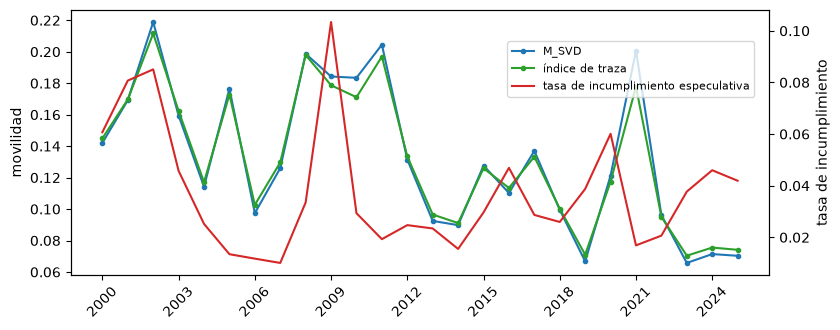

In [6]:
# Movilidad de la matriz agrupada, la serie anual versionada y su relación con la tasa de incumplimiento especulativa
mob = out["mobility"]
svd = np.array([np.nan if v is None else v for v in mob["svd"]])
trace = np.array([np.nan if v is None else v for v in mob["trace"]])
spec = np.array([np.nan if v is None else v for v in mob["spec_default_rate"]])
ok = np.isfinite(svd) & np.isfinite(spec)
labels = mob["labels"]

print("matriz agrupada: M_SVD =", round(mobility.svd_mobility(P), 4), "| índice de traza =", round(mobility.trace_mobility(P), 4))
print("año más móvil:", labels[int(np.nanargmax(svd))], round(float(np.nanmax(svd)), 4), "| menos móvil:", labels[int(np.nanargmin(svd))], round(float(np.nanmin(svd)), 4))
print("años con ambas series:", int(ok.sum()), "| correlación de M_SVD con la tasa de incumplimiento especulativa:", round(float(np.corrcoef(svd[ok], spec[ok])[0, 1]), 3))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(labels, svd, color="tab:blue", marker="o", markersize=3, label="M_SVD")
ax.plot(labels, trace, color="tab:green", marker="o", markersize=3, label="índice de traza")
ax.set_ylabel("movilidad")
ax2 = ax.twinx()
ax2.plot(labels, spec, color="tab:red", label="tasa de incumplimiento especulativa")
ax2.set_ylabel("tasa de incumplimiento")
ax.set_xticks(range(0, len(labels), 3))
ax.set_xticklabels(labels[::3], rotation=45)
fig.legend(loc="upper right", fontsize=8, bbox_to_anchor=(0.9, 0.88))
fig.tight_layout()
plt.show()

### Paso 5: orden y momentum, sobre trayectorias cuya verdad se conoce

Otras dos desviaciones del modelo de Markov importan en la práctica. La prueba de **orden** (Anderson y Goodman, ecuación 3.12) pregunta si el estado siguiente depende también del anterior y no solo del actual. El valor por defecto del motor agrupa los estados anterior y siguiente por dirección (desde un grado mejor, el mismo, uno peor; hacia uno mejor, el mismo, uno peor), la agrupación sobre la que actúa el momentum. La prueba de **momentum** (dos Reis, Pfeuffer y Smith, 2020) ajusta la intensidad de salida de un grado como $\lambda(t) = q_i(t)\, e^{cZ}$ con $Z = 1$ para un deudor rebajado hasta su grado actual, y prueba $c = 0$ con una razón de verosimilitud.

Ninguna puede correr sobre los conteos de CEREP. La celda siguiente saca dos conjuntos de datos del generador versionado, con semilla y el mismo número de deudores: uno de Markov, otro donde cada rebaja sube la intensidad de nuevas rebajas (momentum de `RatingPaths` con fuerza 0,125 y decaimiento 1 por año, la fuerza con que el estudio versionado recupera el coeficiente de intensidad que dos Reis et al. estiman con datos de Moody's). Corre las tres pruebas en cada uno. El motor informa el coeficiente de momentum ajustado $c$, que es 0 para una cadena de Markov.

In [7]:
# Sacar un conjunto de Markov y uno con momentum del generador versionado y correr las tres pruebas en cada uno
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
planted = {"markov": {}, "momentum": dict(momentum=((0.125, 1.0), (0.125, 1.0)), investment_grades=4)}

print(f"{'conjunto':12s}{'p de homogeneidad':>24s}{'p de orden':>16s}{'p de momentum':>18s}{'c ajustado':>14s}")
verdicts = {}
for label, defect in planted.items():
    data = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots, **defect).draw(np.random.default_rng(20261021))
    hom = tests.rating_time_homogeneity([s["counts"] for s in data["steps"]])
    order = tests.rating_markov_order(data["triplets"])
    mom = tests.rating_momentum(data["segments"])
    verdicts[label] = (hom.p_value, order.p_value, mom.p_value)
    name = {"markov": "Markov", "momentum": "momentum"}[label]
    print(f"{name:12s}{hom.p_value:24.3g}{order.p_value:16.3g}{mom.p_value:18.3g}{mom.extras['coefficient']:14.3f}")

conjunto           p de homogeneidad      p de orden     p de momentum    c ajustado
Markov                         0.528            0.16             0.352         0.047
momentum                        0.43        1.96e-13          2.98e-13         0.347


En el conjunto de Markov ninguna prueba rechaza. En el conjunto con momentum las pruebas de orden y de momentum rechazan con un valor p cercano a $10^{-13}$, y la prueba de homogeneidad no rechaza en absoluto: la matriz es la misma cada año, la cadena simplemente no es de Markov. Un rechazo de homogeneidad no puede entonces leerse como momentum, y la ausencia de rechazo no libera a una cadena de él. Un conjunto de datos es una muestra; el estudio versionado de abajo cuenta con qué frecuencia rechaza cada prueba en 200.

In [8]:
# Leer los estudios de potencia versionados: tasas de rechazo al 5% a lo largo de la escala de momentum y de la escala de estrés
def rate(study, test_id, rung):
    row = next(s for s in study["outputs"]["simulations"] if s["test_id"] == test_id and s["rung"] == rung)
    return row["rates"]["p<0.05"]["rate"]

alphas = momentum["outputs"]["ladder"]["values"]
print(momentum["outputs"]["simulations"][0]["n_rep"], "conjuntos por fila")
print(f"{'fuerza del momentum':24s}" + "".join(f"{a:>8.3f}" for a in alphas))
for test_id, label in (("rating.time_homogeneity", "homogeneidad"), ("rating.markov_order", "orden"), ("rating.momentum", "momentum")):
    print(f"{label:24s}" + "".join(f"{rate(momentum, test_id, a):8.3f}" for a in alphas))
factors = cycle["outputs"]["ladder"]["values"]
print(f"{'estrés k del tercer año':24s}" + "".join(f"{k:>8.2f}" for k in factors))
for test_id, label in (("rating.time_homogeneity", "homogeneidad"), ("rating.matrix_reference", "año vs agrupada")):
    print(f"{label:24s}" + "".join(f"{rate(cycle, test_id, k):8.3f}" for k in factors))

200 conjuntos por fila
fuerza del momentum        0.000   0.025   0.050   0.125   0.250
homogeneidad               0.035   0.030   0.045   0.085   0.115
orden                      0.085   0.110   0.335   1.000   1.000
momentum                   0.050   0.350   0.865   1.000   1.000
estrés k del tercer año     1.00    1.25    1.50    2.00    3.00
homogeneidad               0.040   0.295   0.980   1.000   1.000
año vs agrupada            0.000   0.275   0.995   1.000   1.000


### Paso 6: la cadena frente a la cohorte que la vivió

El sentido de una matriz es una proyección. El artefacto guarda, para cinco ventanas de cinco años, la cohorte fija del primer año de la ventana seguida hasta el final (`outputs.lifetime`) junto a lo que proyectan las matrices anuales de la ventana. Hay que distinguir tres números. **Vivido, incumplido (`cumulative_d2`)**: todo incumplido calificado, de la página de incumplimientos. **Vivido, en incumplimiento al final (`default_end`)**: calificaciones que siguen en una categoría de incumplimiento en la página de transiciones al final de la ventana, lo que pierde los incumplimientos retirados o recalificados dentro de la ventana. **Encadenado**: las cinco matrices anuales de la ventana multiplicadas, con los retiros como estado absorbente, de modo que una calificación que cayó en incumplimiento cuenta; por definición queda entre los otros dos. La matriz agrupada a la quinta y el generador EM proyectan el mismo horizonte sin las matrices de la ventana. La celda imprime la última ventana para los grados B y CCC-C y la fracción retirada.

In [9]:
# La última ventana de cinco años: fracciones de incumplimiento a cinco años vividas y proyectadas para B y CCC-C, y la fracción retirada
window = out["lifetime"][-1]
print("ventana:", window["label"], "| tamaños de cohorte B y CCC-C:", window["size"][5], window["size"][6])
rows = (
    ("vivido: todo incumplido (cumulative_d2)", window["observed"]["cumulative_d2"]),
    ("vivido: en incumplimiento al final (default_end)", window["observed"]["default_end"]),
    ("matrices anuales encadenadas, retiros como estado", window["projected"]["chain_state"]),
    ("encadenadas, retiros removidos", window["projected"]["chain_exclude"]),
    ("matriz agrupada a la quinta", window["projected"]["pooled_power"]),
    ("generador EM, cinco años", window["projected"]["em"]),
    ("fracción retirada al final", window["observed"]["withdrawn_end"]),
)
print(f"{'':74s}{'B':>10s}{'CCC-C':>10s}")
for label, values in rows:
    print(f"{label:74s}{values[5]:10.4f}{values[6]:10.4f}")
print("lo encadenado queda entre los dos números vividos (B y CCC-C):",
      [si_no(window["observed"]["default_end"][g] <= window["projected"]["chain_state"][g] <= window["observed"]["cumulative_d2"][g]) for g in (5, 6)])

ventana: 2020-2024 | tamaños de cohorte B y CCC-C: 1846 238
                                                                                   B     CCC-C
vivido: todo incumplido (cumulative_d2)                                       0.1126    0.6144
vivido: en incumplimiento al final (default_end)                              0.0060    0.0000
matrices anuales encadenadas, retiros como estado                             0.0259    0.0910
encadenadas, retiros removidos                                                0.0440    0.2047
matriz agrupada a la quinta                                                   0.0821    0.2530
generador EM, cinco años                                                      0.0821    0.2527
fracción retirada al final                                                    0.5531    0.8109
lo encadenado queda entre los dos números vividos (B y CCC-C): ['sí', 'sí']


## Resultados

- **La matriz no es la misma cada año.** El chi-cuadrado anual es 12.028,16 con 1.075 grados de libertad (11,2 veces sus grados de libertad; el valor p cae a 0, rojo) y el semestral 14.248,61 con 899 (15,9 veces). AA aporta lo máximo por grado de libertad (32,9) y CCC-C lo mínimo (3,1). Cada uno de los 26 años rechaza también la matriz agrupada (el estadístico sobre sus grados de libertad va de 2,27 en 2012 a 55,27 en 2021), sin movimientos imposibles. Todo iguala los valores versionados.
- **Las pruebas de estabilidad del BCE.** El ancho de banda ponderado de la matriz de 2000 es 0,268 para bajadas y 0,288 para subidas; es descriptivo y no lleva luz. Las pruebas z de migración, con ajuste de Holm entre celdas, señalan 2 de las 26 cohortes al 5% (2001 tiene p = 0,0099). Todo iguala las filas versionadas.
- **Movilidad.** La matriz agrupada tiene M_SVD 0,135 e índice de traza 0,137. El año más móvil es 2002 (0,219) y el menos móvil 2023 (0,066). En los 26 años M_SVD se correlaciona 0,27 con la tasa de incumplimiento especulativa: movimiento e incumplimiento se relacionan, pero distan de ser lo mismo.
- **La homogeneidad no puede ver el momentum.** En el conjunto de Markov con semilla ninguna prueba rechaza (p = 0,53, 0,16 y 0,35; c ajustado = 0,05). En el conjunto con momentum la prueba de orden (p = 2e-13) y la de momentum (p = 3e-13, c ajustado = 0,35) rechazan y la de homogeneidad no (p = 0,43). En el estudio versionado de 200 conjuntos, con fuerza de momentum 0,125 la prueba de homogeneidad rechaza el 8,5% de los conjuntos al 5% (3,5% sin momentum), las de orden y de momentum el 100%. Un tercer año estresado, en cambio, lo ve la homogeneidad: 29,5% con k = 1,25, 98% con k = 1,5.
- **Encadenado frente a vivido.** En la ventana 2020 a 2024, el 61,4% de la cohorte CCC-C cayó en incumplimiento (todo incumplido calificado) mientras ninguna seguía en incumplimiento al final y el 81,1% se había retirado; las matrices anuales encadenadas dan 9,1% y la matriz agrupada a la quinta 25,3%. Para B los números son 11,3% vivido, 2,6% encadenado, 8,2% agrupada a la quinta, 55,3% retirado. Lo encadenado queda entre las dos lecturas vividas, como dice su definición; con el 81,1% de la cohorte CCC-C salida por retiro, la comparación no puede separar una falla de la cadena de Markov de la forma de contar los retiros.

Lo que este cuaderno no muestra: cómo llevar una curva de PD a un año nuevo (cuaderno 05), ni cuánto cuesta una PD en capital (cuaderno 07).

## Resumen

- La homogeneidad en el tiempo, la prueba de cada año contra la agrupada, la prueba de orden y la de momentum plantean preguntas distintas; el rechazo de una no nombra la desviación, y un resultado favorable no libera a la cadena de las demás.
- El ancho de banda ponderado del BCE es descriptivo y sus pruebas z de migración, ajustadas entre celdas, señalan pocas cohortes aquí; los índices de movilidad se mueven con el ciclo pero no son la tasa de incumplimiento.
- Los conteos de calificaciones solos sostienen la homogeneidad y las pruebas del BCE; el orden y el momentum necesitan trayectorias, así que corren sobre trayectorias simuladas de verdad conocida.
- Una proyección se compara con lo que vivió una cohorte solo después de decir cuál de los tres números de incumplimiento cuenta cada una.

**Qué probar después.** Cambia la fuerza del momentum en la simulación del Paso 5 a 0,05 y corre de nuevo con otras semillas; luego lee el cuaderno 05.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuaciones 3.1, 3.5, 3.8 y 3.12. https://doi.org/10.1214/aoms/1177707039
- BCE (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.5 (ancho de banda ponderado de la matriz y pruebas z de migración). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Jafry, Y. y Schuermann, T. (2004), Measurement, estimation and comparison of credit migration matrices, Journal of Banking and Finance 28(11), para los índices de movilidad.
- dos Reis, G., Pfeuffer, M. y Smith, G. (2020), Capturing model risk and rating momentum in the estimation of probabilities of default and credit rating migrations, Quantitative Finance, arXiv 1809.09889.
- Holm, S. (1979), A simple sequentially rejective multiple test procedure, Scandinavian Journal of Statistics 6(2), para el ajuste entre celdas.